# SortFlow

1. 环境与依赖检查
2. 参数与路径配置(**在第 2 节自行修改**)
3. 加载 `SortFlow` (Encoder + NeuralODE 推理)
4. 加载并展示 Content / Style 图
5. 单对推理 + 推理耗时
6. 结果对比可视化
7. 指标评估 (DISTS / Color Histogram Loss)
   - 7.5 多域 DISTS (Grayscale / LDC edge / HED edge)

## 1. 环境与依赖检查

In [1]:
import os, sys, time
import torch
from PIL import Image
from torchvision import transforms
from torchvision.utils import save_image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

print('Python      :', sys.version.split()[0])
print('PyTorch     :', torch.__version__)
print('CUDA 可用   :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU         :', torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('使用设备    :', device)

Python      : 3.11.4
PyTorch     : 2.1.0+cu121
CUDA 可用   : True
GPU         : NVIDIA GeForce RTX 4050 Laptop GPU
使用设备    : cuda


## 2. 参数与路径配置

> **答辩演示时,可在这里直接修改 `CONTENT_PATH` 与 `STYLE_PATH` 切换演示图片。**
> 流匹配特有的两个超参:`STEPS` (2~100) 和 `STRENGTH` (0~1)。

In [10]:
# === 演示用 content / style 图 (在这里改) ===
CONTENT_PATH = r"E:\备份\sortflow\content\0000001.png"
STYLE_PATH   = r"E:\备份\sortflow\style\0000001.png"

# === SortFlow 编码器权重 ===
ENCODER_PATH = r"E:\备份\sortflow\sortflow_encoder_V7_epoch_750000.pt"
#ENCODER_PATH = r"E:\备份\sortflow\sortflow_encoder_iter_751001.pt"

# === 推理 / 显示参数 ===
IMAGE_SIZE = 512        # 仅用于加载/可视化/DISTS;模型内部固定 528
STEPS      = 8          # 流步数, 2~100
STRENGTH   = 1.0        # 风格强度, 0~1
OUTPUT_DIR = r"E:\备份\sortflow\results_demo"

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert 2 <= STEPS <= 100,   f"STEPS 必须 2~100, 当前 {STEPS}"
assert 0.0 <= STRENGTH <= 1.0, f"STRENGTH 必须 0~1, 当前 {STRENGTH}"

# 路径自检,避免现场翻车
for tag, p in [('CONTENT', CONTENT_PATH), ('STYLE', STYLE_PATH),
               ('ENCODER', ENCODER_PATH)]:
    flag = '存在' if os.path.exists(p) else '缺失'
    print(f'[{flag}] {tag:8s} -> {p}')
print(f'STEPS={STEPS}  STRENGTH={STRENGTH}  IMAGE_SIZE={IMAGE_SIZE}')

[存在] CONTENT  -> E:\备份\sortflow\content\0000001.png
[存在] STYLE    -> E:\备份\sortflow\style\0000001.png
[存在] ENCODER  -> E:\备份\sortflow\sortflow_encoder_iter_751001.pt
STEPS=8  STRENGTH=1.0  IMAGE_SIZE=512


## 3. 加载 `SortFlow`

`SortFlow` 由两部分组成:

- **Encoder**: `src.encoder.Encoder(k_dim=8195, input_dim=4, hidden=1024, output_dim=3)`,把图像编码成 NeuralODE 的参数向量
- **NeuralODE 流匹配推理**: `src.inference2.run_inference` 内部基于 luma 排序后做 `sample → inv_sample` 完成颜色迁移,叠回高频残差作为最终输出

In [3]:
# === SortFlow 核心定义 (内联 Encoder + run_inference) ===
import sys
sys.path.insert(0, r"E:\备份\sortflow")  # 让 NeuralODE 可被导入

import os
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision.transforms import v2
from einops import einsum
from PIL import Image
import cv2

from src.neural_ode import NeuralODE  # 仅 NeuralODE 仍走 import (149 行,保持 cell 紧凑)

INPUT_SIZE = 528


# ---------- Encoder (内联自 src/encoder.py) ----------
class Encoder(nn.Module):
    """EfficientNet 主干, 把图像编码成 NeuralODE 的参数向量。"""

    def __init__(self, k_dim, input_dim, hidden, output_dim, device, encoder_type="B6"):
        super().__init__()
        self.k_dim = k_dim
        if encoder_type == "B6":
            self.model = torchvision.models.efficientnet_b6(num_classes=k_dim)
            self.resize = torchvision.models.efficientnet.EfficientNet_B6_Weights.IMAGENET1K_V1.transforms()
        elif encoder_type == "B0":
            self.model = torchvision.models.efficientnet_b0(num_classes=k_dim)
            self.resize = torchvision.models.efficientnet.EfficientNet_B0_Weights.IMAGENET1K_V1.transforms()

        self.device = device
        self.input_dim = input_dim
        self.hidden = hidden
        self.output_dim = output_dim
        # k_dim 个参数会被切成 NeuralODE 4 层权重 (W0, b0, W1, b1)
        self.splits = [
            0,
            input_dim * hidden,
            input_dim * hidden + hidden,
            input_dim * hidden + hidden + output_dim * hidden,
            input_dim * hidden + hidden + output_dim * hidden + output_dim,
        ]
        self.to(device)

    def forward(self, im1):
        with torch.no_grad():
            im1 = self.resize(im1)
        return self.model(im1)

    def apply_e(self, e, x, t):
        """把编码向量 e 当成 MLP 权重, 对 (x, t) 做前向。"""
        splits = self.splits
        batch_size = e.shape[0]
        shapes = [
            torch.Size([batch_size, self.hidden, self.input_dim]),
            torch.Size([batch_size, self.hidden]),
            torch.Size([batch_size, self.output_dim, self.hidden]),
            torch.Size([batch_size, self.output_dim]),
        ]
        e0 = e[:, splits[0]:splits[1]].reshape(shapes[0])
        e1 = e[:, splits[1]:splits[2]].reshape(shapes[1])
        e2 = e[:, splits[2]:splits[3]].reshape(shapes[2])
        e3 = e[:, splits[3]:splits[4]].reshape(shapes[3])
        e1 = e1.unsqueeze(1)
        e3 = e3.unsqueeze(1)
        xt = torch.cat([x, t], dim=-1)
        xt = einsum(xt, e0, 'i j k, i n k -> i j n') + e1
        xt = torch.tanh(xt)
        xt = einsum(xt, e2, 'i j k, i n k -> i j n') + e3
        return xt


# ---------- 预处理: 引导滤波分离低频 / 高频 ----------
def enc_preprocess(pil_image, crop=False, image=False, rand_trans=False,
                   radius=4, eps=1e-2):
    im = pil_image
    im_size = (INPUT_SIZE, INPUT_SIZE)

    if crop:
        im = v2.CenterCrop(min(im.size))(im)
    im = v2.Resize(im_size)(im)
    if rand_trans:
        im = v2.RandomHorizontalFlip(p=0.5)(im)
        im = v2.functional.rotate(im, angle=np.random.choice([0, 90, -90, 180]))
    if image:
        return im

    im_np = np.array(im, dtype=np.float32) / 255.0  # H W C
    if im_np.ndim == 2:
        im_np = np.stack([im_np] * 3, axis=-1)
    if im_np.ndim == 3 and im_np.shape[2] == 4:
        im_np = im_np[:, :, :3]
    if im_np.ndim != 3 or im_np.shape[2] != 3:
        raise ValueError(f"Image shape error: {im_np.shape}")

    # cv2.ximgproc.guidedFilter 逐通道去掉高频, 保留 low_freq;残差即 high_freq
    guided_low = np.zeros_like(im_np)
    try:
        for c in range(3):
            guided_low[:, :, c] = cv2.ximgproc.guidedFilter(
                guide=im_np[:, :, c].astype(np.float32),
                src=im_np[:, :, c].astype(np.float32),
                radius=radius, eps=eps,
            )
    except Exception as e:
        print(f"Guided Filter Error: {e}")
        return None, None

    high_freq = im_np - guided_low
    low_freq_tensor  = torch.tensor(guided_low).permute(2, 0, 1)   # 3, H, W
    high_freq_tensor = torch.tensor(high_freq).permute(2, 0, 1)
    return low_freq_tensor, high_freq_tensor


# ---------- 张量 → PIL ----------
def tensor_to_im(tensor, w, h):
    tensor = tensor.detach().cpu()
    if tensor.dim() == 3 and tensor.shape[0] == 3:
        tensor = tensor.permute(1, 2, 0)
    elif tensor.dim() == 2 and tensor.shape[1] == 3:
        tensor = tensor.reshape(h, w, 3)
    tensor = torch.clamp(tensor, 0, 1) * 255
    return Image.fromarray(tensor.numpy().astype(np.uint8))


# ---------- run_inference: 主流程 (encode → 排序匹配 flow → 叠回高频) ----------
def run_inference(encoder, device, content_im_path, style_im_path,
                  enc_steps=3, strength=1.0, crop=False, save_dir=None, **_):
    with torch.no_grad():
        encoder.eval()

        content_im = Image.open(content_im_path).convert('RGB')
        style_im   = Image.open(style_im_path).convert('RGB')
        if crop:
            content_im = v2.CenterCrop(min(content_im.size))(content_im)
            style_im   = v2.CenterCrop(min(style_im.size))(style_im)

        # 1. content 拆低频/高频, EfficientNet 编成 base flow 参数
        base_im, high_im = enc_preprocess(content_im, crop)
        base_im = base_im.to(device)
        high_im = high_im.to(device)
        base_e = encoder(base_im.unsqueeze(0)).flatten()
        base_flow = NeuralODE(input_dim=3, hidden=encoder.hidden, device=device)
        base_flow.set_weights(base_e)

        # 2. style 同样编成 target flow 参数
        targ_im, _ = enc_preprocess(style_im, crop)
        targ_im = targ_im.to(device)
        targ_e = encoder(targ_im.unsqueeze(0)).flatten()
        targ_flow = NeuralODE(input_dim=3, hidden=encoder.hidden, device=device)
        targ_flow.set_weights(targ_e)

        # 3. content 低频展平后按亮度排序, 走 base flow 到隐空间, 再用 target flow 反推
        _, h, w = base_im.shape
        base_x = base_im.permute(1, 2, 0).reshape(-1, 3)   # N×3
        luma = base_x.mean(dim=1)
        _, idx = torch.sort(luma)
        base_flat_sorted = base_x[idx]

        latent_x = base_flow.sample(base_flat_sorted, N=enc_steps, strength=strength)
        styled_x = targ_flow.inv_sample(latent_x, N=enc_steps, strength=strength)

        # 4. 按原顺序 scatter 回像素位置, 加上高频残差 → 最终结果
        restored = torch.zeros_like(styled_x)
        restored.scatter_(0, idx.unsqueeze(1).expand(-1, 3), styled_x)
        styled_low = restored.reshape(h, w, 3).permute(2, 0, 1)
        styled_final = torch.clamp(styled_low + high_im, 0, 1)

        styled_im = tensor_to_im(styled_final, w, h)
        latent_im = tensor_to_im(latent_x, w, h)
        return content_im, latent_im, styled_im, style_im

In [11]:
encoder = Encoder(k_dim=8195, input_dim=4, hidden=1024, output_dim=3, device=device)
encoder.load_state_dict(torch.load(ENCODER_PATH, map_location=device))
encoder.to(device).eval()

total_params = sum(p.numel() for p in encoder.parameters())
print(f'编码器参数量: {total_params/1e6:.2f} M')
print(f'权重: {ENCODER_PATH}')

编码器参数量: 59.63 M
权重: E:\备份\sortflow\sortflow_encoder_iter_751001.pt


## 4. 图像加载与预览

Content tensor: (1, 3, 512, 512)
Style   tensor: (1, 3, 512, 512)


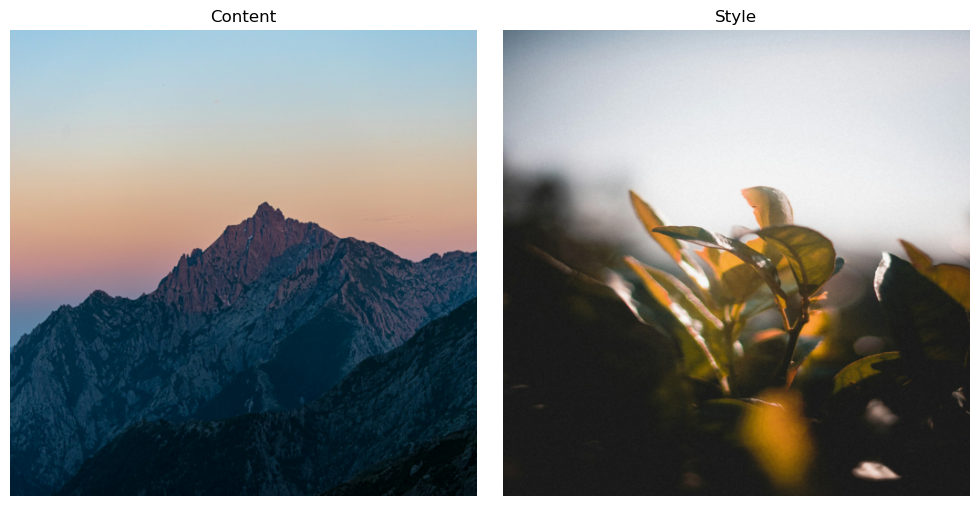

In [5]:
def load_image(path, size=IMAGE_SIZE, device=device):
    if not os.path.exists(path):
        raise FileNotFoundError(f'Image not found: {path}')
    transform = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
    ])
    img = Image.open(path).convert('RGB')
    return transform(img).unsqueeze(0).to(device)


def tensor_to_np(t):
    return t.detach().squeeze(0).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


content_img = load_image(CONTENT_PATH)
style_img   = load_image(STYLE_PATH)
print('Content tensor:', tuple(content_img.shape))
print('Style   tensor:', tuple(style_img.shape))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(tensor_to_np(content_img)); axes[0].set_title('Content'); axes[0].axis('off')
axes[1].imshow(tensor_to_np(style_img));   axes[1].set_title('Style');   axes[1].axis('off')
plt.tight_layout(); plt.show()

## 5. 单对推理 + 耗时统计

In [12]:
with torch.no_grad():
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.time()
    # run_inference 返回 (content_pil, latent_pil, styled_pil, style_pil)
    imgs = run_inference(encoder, device, CONTENT_PATH, STYLE_PATH,
                         enc_steps=STEPS, strength=STRENGTH, save_dir=None)
    output_pil = imgs[2]
    if device.type == 'cuda':
        torch.cuda.synchronize()
    dt = time.time() - t0

print(f'输入: {IMAGE_SIZE}x{IMAGE_SIZE}  STEPS={STEPS}  STRENGTH={STRENGTH}  推理耗时: {dt*1000:.1f} ms')

save_name = os.path.splitext(os.path.basename(CONTENT_PATH))[0] + '_stylized.png'
save_path = os.path.join(OUTPUT_DIR, save_name)
output_pil.save(save_path)
print('结果已保存:', save_path)

# 把 PIL 转回 [1,3,H,W] tensor,后面几节都要用
output = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])(output_pil).unsqueeze(0).to(device).clamp(0, 1)

输入: 512x512  STEPS=8  STRENGTH=1.0  推理耗时: 1000.7 ms
结果已保存: E:\备份\sortflow\results_demo\0000001_stylized.png


## 6. Content / Style / Output 三栏对比

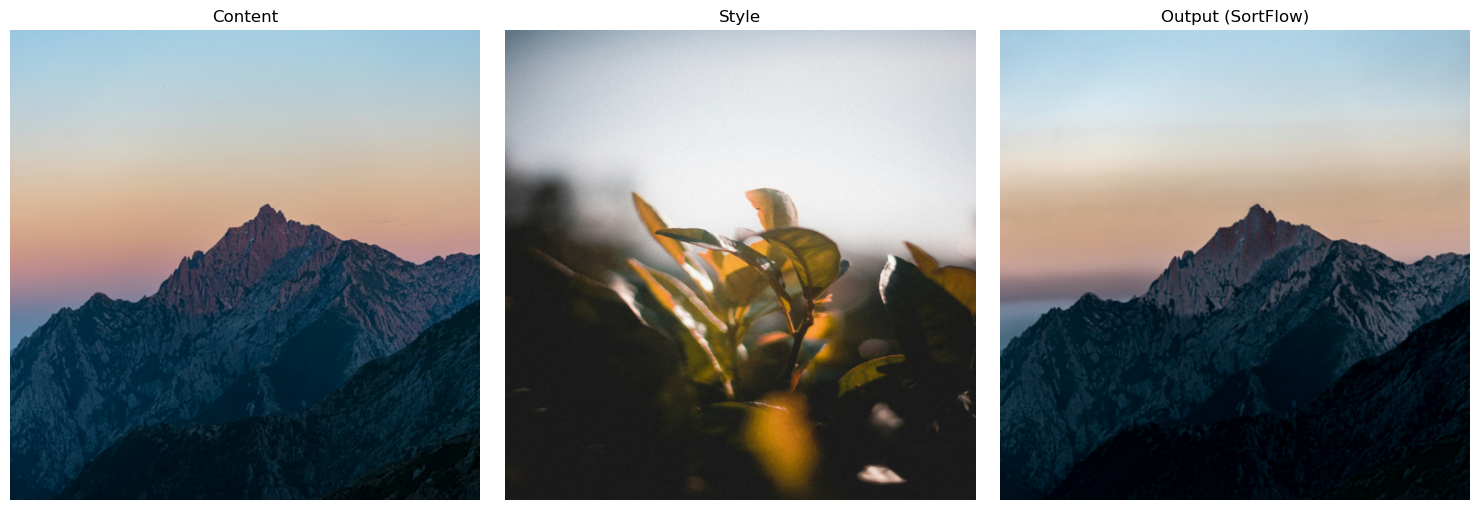

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(tensor_to_np(content_img)); axes[0].set_title('Content'); axes[0].axis('off')
axes[1].imshow(tensor_to_np(style_img));   axes[1].set_title('Style');   axes[1].axis('off')
axes[2].imshow(tensor_to_np(output));      axes[2].set_title('Output (SortFlow)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

## 7. 指标评估

- **DISTS**:衡量输出与 content 的结构/纹理一致性,越低越好
- **HistLoss**:衡量输出与 style 的颜色直方图距离,越低越好

In [15]:
from metrics import MetricCalculator

evaluator = MetricCalculator(device=device)
scores = evaluator.compute(content_img, style_img, output)

print('=' * 30)
for k, v in scores.items():
    print(f'{k:10s}: {v:.4f}')
print('=' * 30)

DISTS     : 0.1261
HistLoss  : 0.4923


## 7.5 多域 DISTS 评估 (Grayscale / LDC edge / HED edge)

**独立单元格** —— 直接从磁盘读 `content` 和**之前已生成的** stylized 输出,不依赖前面任何 cell。
把两张图分别投影到 灰度 / LDC 边缘 / HED 边缘 三个域,各自计算 DISTS,衡量结构 / 边缘 / 亮度是否被风格迁移破坏。

- **LDC**: `D:\code\sample\LDC-main` (modelB4 + BIPED checkpoint)
- **HED**: `D:\code\sample\pytorch-hed-master\network-bsds500.pytorch`

content: (1, 3, 512, 512) (E:\备份\sortflow\content\0000001.png)
output : (1, 3, 512, 512) (E:\备份\sortflow\results_demo\0000001_stylized.png)
LDC loaded.
HED loaded.
DISTS (content ↔ output) 多域评估
--------------------------------------------
  Grayscale       : 0.0883
  LDC  edge (B4)  : 0.1188
  HED  edge       : 0.1272


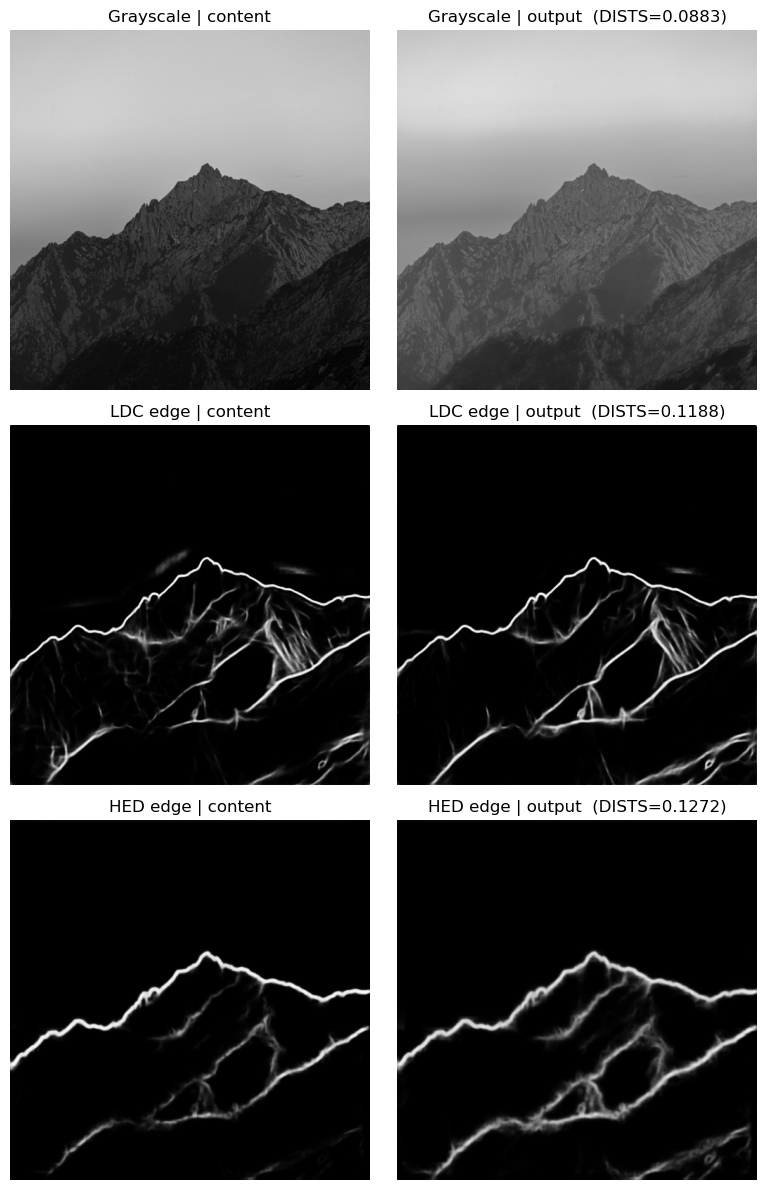

In [9]:
# ========== 多域 DISTS:Grayscale / LDC / HED (独立 cell) ==========
# 直接读盘:content + 之前已生成的 stylized,无需 SortFlow 推理

import sys
sys.path.insert(0, r"D:\code\sample\LDC-main")  # 让 modelB4 可 import

import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

from DISTS_pytorch import DISTS as _DISTS
from modelB4 import LDC as _LDCModel

# ---- 0. 配置:在这里修改要对比的两张图 ----
CONTENT_FOR_EVAL = r"E:\备份\sortflow\content\0000001.png"
OUTPUT_FOR_EVAL  = r"E:\备份\sortflow\results_demo\0000001_stylized.png"
IMG_SIZE = 512

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _load_img(path, size=IMG_SIZE):
    tr = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])
    return tr(Image.open(path).convert("RGB")).unsqueeze(0).to(device)


def _to_np(t):
    return t.detach().squeeze(0).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


content_eval = _load_img(CONTENT_FOR_EVAL)
output_eval  = _load_img(OUTPUT_FOR_EVAL)
print(f"content: {tuple(content_eval.shape)} ({CONTENT_FOR_EVAL})")
print(f"output : {tuple(output_eval.shape)} ({OUTPUT_FOR_EVAL})")

# ---- 1. LDC (modelB4 + BIPED checkpoint) ----
LDC_CKPT = r"D:\code\sample\LDC-main\checkpoints\BIPED\16\16_model.pth"
LDC_MEAN_BGR = torch.tensor([103.939, 116.779, 123.68], device=device).view(1, 3, 1, 1)

ldc_model = _LDCModel().to(device)
ldc_model.load_state_dict(torch.load(LDC_CKPT, map_location=device))
ldc_model.eval()
for _p in ldc_model.parameters():
    _p.requires_grad = False
print("LDC loaded.")

# ---- 2. HED (内联 Network, 跳过原作者 run.py 中的联网下载, 加载本地权重) ----
HED_CKPT = r"D:\code\sample\pytorch-hed-master\network-bsds500.pytorch"
HED_MEAN_BGR = torch.tensor([104.00698793, 116.66876762, 122.67891434],
                            device=device).view(1, 3, 1, 1)


class _HEDNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.netVggOne = nn.Sequential(
            nn.Conv2d(3, 64, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(64, 64, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggTwo = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(128, 128, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggThr = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(256, 256, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(256, 256, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggFou = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(256, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggFiv = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netScoreOne = nn.Conv2d(64, 1, 1)
        self.netScoreTwo = nn.Conv2d(128, 1, 1)
        self.netScoreThr = nn.Conv2d(256, 1, 1)
        self.netScoreFou = nn.Conv2d(512, 1, 1)
        self.netScoreFiv = nn.Conv2d(512, 1, 1)
        self.netCombine = nn.Sequential(nn.Conv2d(5, 1, 1), nn.Sigmoid())

    def forward(self, x_rgb01):
        x = x_rgb01[:, [2, 1, 0], :, :] * 255.0 - HED_MEAN_BGR
        v1 = self.netVggOne(x)
        v2 = self.netVggTwo(v1)
        v3 = self.netVggThr(v2)
        v4 = self.netVggFou(v3)
        v5 = self.netVggFiv(v4)
        H, W = x.shape[2], x.shape[3]

        def up(s, f):
            return F.interpolate(s(f), size=(H, W), mode='bilinear', align_corners=False)

        cat = torch.cat([up(self.netScoreOne, v1),
                         up(self.netScoreTwo, v2),
                         up(self.netScoreThr, v3),
                         up(self.netScoreFou, v4),
                         up(self.netScoreFiv, v5)], dim=1)
        return self.netCombine(cat)


hed_model = _HEDNet().to(device)
_hed_sd = torch.load(HED_CKPT, map_location=device)
hed_model.load_state_dict({k.replace('module', 'net'): v for k, v in _hed_sd.items()})
hed_model.eval()
for _p in hed_model.parameters():
    _p.requires_grad = False
print("HED loaded.")

# ---- 3. 三种投影:gray / LDC / HED,全部输出 3 通道 ∈ [0,1] ----
_GRAY_W = torch.tensor([0.299, 0.587, 0.114], device=device).view(1, 3, 1, 1)


def to_gray3(x_rgb01):
    g = (x_rgb01 * _GRAY_W).sum(dim=1, keepdim=True)
    return g.repeat(1, 3, 1, 1).clamp(0, 1)


@torch.no_grad()
def to_ldc_edge3(x_rgb01):
    preds = ldc_model(x_rgb01 * 255.0 - LDC_MEAN_BGR)
    return torch.sigmoid(preds[-1]).repeat(1, 3, 1, 1).clamp(0, 1)


@torch.no_grad()
def to_hed_edge3(x_rgb01):
    return hed_model(x_rgb01).repeat(1, 3, 1, 1).clamp(0, 1)

# ---- 4. 计算三个域的 DISTS ----
_dists = _DISTS().to(device).eval()
for _p in _dists.parameters():
    _p.requires_grad = False


@torch.no_grad()
def dpair(a, b):
    return _dists(a, b).item()


with torch.no_grad():
    g_c, g_o = to_gray3(content_eval),     to_gray3(output_eval)
    l_c, l_o = to_ldc_edge3(content_eval), to_ldc_edge3(output_eval)
    h_c, h_o = to_hed_edge3(content_eval), to_hed_edge3(output_eval)
    d_gray = dpair(g_c, g_o)
    d_ldc  = dpair(l_c, l_o)
    d_hed  = dpair(h_c, h_o)

print('=' * 44)
print('DISTS (content ↔ output) 多域评估')
print('-' * 44)
print(f'  Grayscale       : {d_gray:.4f}')
print(f'  LDC  edge (B4)  : {d_ldc:.4f}')
print(f'  HED  edge       : {d_hed:.4f}')
print('=' * 44)

# ---- 5. 可视化 3 行 × 2 列 ----
rows = [
    ('Grayscale', g_c, g_o, d_gray),
    ('LDC edge',  l_c, l_o, d_ldc),
    ('HED edge',  h_c, h_o, d_hed),
]
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for i, (name, c, o, d) in enumerate(rows):
    axes[i, 0].imshow(_to_np(c)); axes[i, 0].set_title(f'{name} | content'); axes[i, 0].axis('off')
    axes[i, 1].imshow(_to_np(o)); axes[i, 1].set_title(f'{name} | output  (DISTS={d:.4f})'); axes[i, 1].axis('off')
plt.tight_layout(); plt.show()